# **5. ĐÁNH GIÁ MÔ HÌNH**

So sánh 6 mô hình đã huấn luyện ở notebook 4: **Baseline, Hybrid, LightGBM, Ridge, Random Forest, XGBoost**. Bài toán là dự báo doanh thu **trước 6 tuần** (yêu cầu gốc của Rossmann), nên mọi mô hình chỉ dùng độ trễ từ 49 ngày bán trở lên. Chỉ số chính là **RMSPE**, chỉ số chính thức của cuộc thi Kaggle. Mọi chỉ số đều tính trên doanh thu thật.

**5.1 Chuẩn bị dữ liệu.**

Đọc các dự đoán đã lưu ở notebook 4 (`data/processed/predictions/`). Mỗi mô hình là một file gồm `Store, Date, Split, actual, pred`; `models.json` ghi tên file và số đặc trưng của mô hình.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

def save_fig(name):
    """Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)

PROCESSED_DIR = Path('data/processed')
PRED_DIR = PROCESSED_DIR / 'predictions'
registry = json.loads((PRED_DIR / 'models.json').read_text(encoding='utf-8'))
n_features = {name: info['n_features'] for name, info in registry.items()}
with open(PROCESSED_DIR / 'config.json', encoding='utf-8') as f:
    cfg = {k: pd.Timestamp(v) for k, v in json.load(f).items()}
VALID_END = cfg['VALID_END']

def load_predictions(models=None, common_rows=True):
    """Gộp dự đoán thành bảng rộng: Store, Date, Split, actual, <tên mô hình>...

    common_rows=True: chỉ giữ dòng mà mọi mô hình đều có dự đoán, để so sánh công bằng
    (Hybrid và Ridge bỏ các dòng thiếu lag).
    """
    keys = ['Store', 'Date', 'Split', 'actual']
    wide = None
    for name in models or registry:
        p = pd.read_parquet(PRED_DIR / registry[name]['file']).rename(columns={'pred': name})
        wide = p if wide is None else wide.merge(p, on=keys, how='inner' if common_rows else 'outer')
    order = {'train': 0, 'valid': 1, 'test': 2}
    return wide.sort_values(['Split', 'Store', 'Date'], ignore_index=True,
                            key=lambda s: s.map(order) if s.name == 'Split' else s)

results = load_predictions()
MODELS = list(registry)
print('Các mô hình:', MODELS)
results.groupby('Split', sort=False).size()

Các mô hình: ['Baseline', 'Hybrid', 'LightGBM', 'Ridge', 'Random Forest', 'XGBoost']


Split
train    683997
valid     43098
test      46998
dtype: int64

Hybrid và Ridge bỏ khoảng 2 tháng đầu của tập train (chưa đủ 63 ngày để có `lag_63`), nên bảng chung chỉ giữ các dòng mà **cả 6 mô hình** đều có dự đoán. Tập kiểm định và tập kiểm tra không bị ảnh hưởng.

Ghép thêm vài thông tin của từng ngày (khuyến mãi, thứ, loại cửa hàng) để phân tích sai số theo nhóm.

In [2]:
info = pd.read_csv(PROCESSED_DIR / 'rossmann_add_features.csv', parse_dates=['Date'],
                   usecols=['Store', 'Date', 'DayOfWeek', 'Promo', 'StoreType'])
results = results.merge(info, on=['Store', 'Date'], how='left')
test = results[results['Split'] == 'test'].copy()
print('Doanh thu trung bình tập kiểm tra:', round(test['actual'].mean(), 1))
print('Tập kiểm tra:', test['Date'].min().date(), '→', test['Date'].max().date(),
      f'({test["Date"].nunique()} ngày, {test["Store"].nunique()} cửa hàng)')

Doanh thu trung bình tập kiểm tra: 7114.5
Tập kiểm tra: 2015-06-13 → 2015-07-31 (49 ngày, 1115 cửa hàng)


**5.2 Bảng chỉ số đánh giá**

So sánh các mô hình trên cùng tập dòng. R² hiệu chỉnh trừ điểm các mô hình dùng nhiều đặc trưng; với hơn 40.000 dòng mỗi tập thì nó gần như bằng R².

In [3]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

def rmspe(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    mask = y_true != 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

def evaluate(actual, pred, n_feature):
    n, r2 = len(actual), r2_score(actual, pred)
    return {'MAE':    mean_absolute_error(actual, pred),
            'RMSE':   root_mean_squared_error(actual, pred),
            'R2':     r2,
            'Adj_R2': 1 - (1 - r2) * (n - 1) / (n - n_feature - 1),
            'RMSPE':  rmspe(actual, pred)}

rows = []
for split, part in results.groupby('Split', sort=False):
    for name in MODELS:
        rows.append({'Tập': split, 'Mô hình': name, **evaluate(part['actual'], part[name], n_features[name])})
metrics = pd.DataFrame(rows)
base = metrics[metrics['Mô hình'] == 'Baseline'].set_index('Tập')['RMSPE']
metrics['Cải thiện RMSPE so với baseline (%)'] = 100 * (1 - metrics['RMSPE'] / metrics['Tập'].map(base))
metrics.to_csv(PROCESSED_DIR / 'metrics.csv', index=False)

ROUND = {'MAE': 1, 'RMSE': 1, 'R2': 4, 'Adj_R2': 4, 'RMSPE': 4, 'Cải thiện RMSPE so với baseline (%)': 1}
print('Tập kiểm tra (sắp theo RMSPE):')
metrics[metrics['Tập'] == 'test'].sort_values('RMSPE').round(ROUND)

Tập kiểm tra (sắp theo RMSPE):


,Tập,Mô hình,MAE,RMSE,R2,Adj_R2,RMSPE,Cải thiện RMSPE so với baseline (%)
17,test,XGBoost,653.0,949.6,0.9056,0.9055,0.1194,16.6
14,test,LightGBM,654.6,954.0,0.9047,0.9046,0.1208,15.6
16,test,Random Forest,707.1,1033.2,0.8882,0.8881,0.1281,10.5
12,test,Baseline,770.4,1143.8,0.8630,0.8630,0.1432,0.0
13,test,Hybrid,781.3,1097.3,0.8739,0.8738,0.1525,-6.5
15,test,Ridge,893.8,1284.6,0.8272,0.8268,0.1895,-32.4


In [4]:
print('Tập kiểm định (sắp theo RMSPE):')
metrics[metrics['Tập'] == 'valid'].sort_values('RMSPE').round(ROUND)

Tập kiểm định (sắp theo RMSPE):


,Tập,Mô hình,MAE,RMSE,R2,Adj_R2,RMSPE,Cải thiện RMSPE so với baseline (%)
8,valid,LightGBM,595.0,814.9,0.9314,0.9313,0.1064,36.0
11,valid,XGBoost,594.4,813.7,0.9316,0.9315,0.1077,35.2
10,valid,Random Forest,688.8,944.6,0.9078,0.9077,0.1232,25.9
7,valid,Hybrid,819.8,1113.6,0.8719,0.8717,0.1521,8.6
6,valid,Baseline,925.1,1316.3,0.8210,0.8210,0.1663,0.0
9,valid,Ridge,942.6,1337.9,0.8151,0.8147,0.1941,-16.7


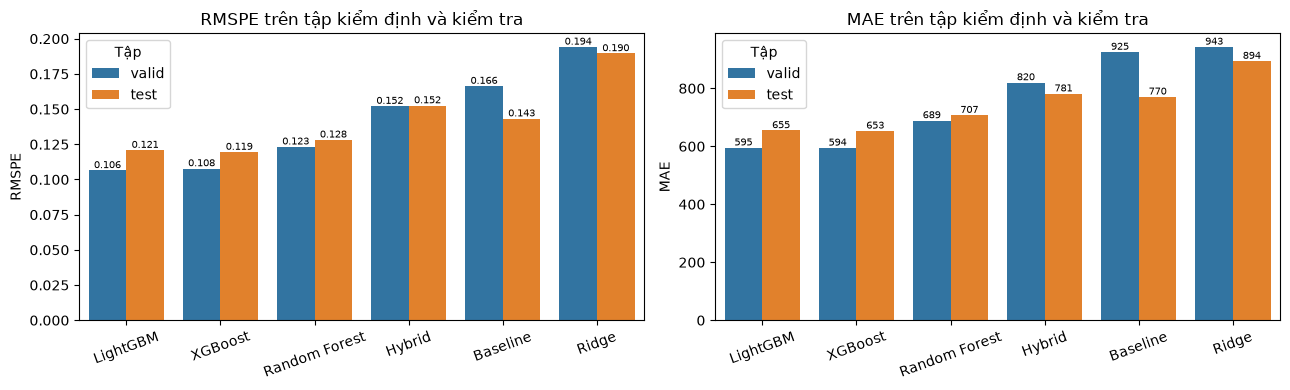

In [5]:
order = metrics[metrics['Tập'] == 'valid'].sort_values('RMSPE')['Mô hình']
eval_metrics = metrics[metrics['Tập'] != 'train']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ['RMSPE', 'MAE']):
    sns.barplot(data=eval_metrics, x='Mô hình', y=metric, hue='Tập', order=order, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f' if metric == 'RMSPE' else '%.0f', fontsize=7)
    ax.set_title(f'{metric} trên tập kiểm định và kiểm tra'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
save_fig('metrics_compare')

**Nhận xét:**
- Ba mô hình cây (**XGBoost, LightGBM, Random Forest**) tốt hơn Baseline ở cả hai tập. Trên tập kiểm tra, XGBoost và LightGBM gần như ngang nhau: RMSPE 0,1194 và 0,1208, MAE khoảng 653–655, tức khoảng 9,2% doanh thu trung bình (7.115). Hai mô hình này giảm RMSPE 16–17% so với Baseline. Random Forest kém hơn một bậc (0,1281).
- **Hybrid** (0,1525) và **Ridge** (0,1895) còn kém Baseline (0,1432) trên tập kiểm tra. Mô hình tuyến tính không bắt được các tương tác phức tạp (cửa hàng × thứ × khuyến mãi) mà Baseline đã có sẵn nhờ tính trung vị theo đúng các nhóm đó.
- Trên tập kiểm định, LightGBM tốt nhất (0,1064), XGBoost sát ngay sau (0,1077); mức cải thiện so với Baseline lên đến 35–36%. Mức cải thiện trên tập kiểm tra nhỏ hơn vì Baseline làm tốt hơn hẳn ở giai đoạn này (0,1432 so với 0,1663 ở tập kiểm định).
- R² hiệu chỉnh gần như bằng R², đúng như dự đoán, vì số dòng lớn hơn rất nhiều so với số đặc trưng.

**5.3 Kiểm tra quá khớp**

So sánh sai số trên tập đã học (train) với hai tập chưa thấy (valid, test). Khoảng cách càng lớn thì mô hình càng học thuộc dữ liệu train.

In [6]:
gap = metrics.pivot(index='Mô hình', columns='Tập', values='RMSPE')[['train', 'valid', 'test']]
gap['test / train'] = gap['test'] / gap['train']
gap.loc[order].round(4)

Tập,train,valid,test,test / train
Mô hình,,,,
LightGBM,0.0900,0.1064,0.1208,1.3429
XGBoost,0.0685,0.1077,0.1194,1.7443
Random Forest,0.0742,0.1232,0.1281,1.7268
Hybrid,0.1298,0.1521,0.1525,1.1748
Baseline,0.2246,0.1663,0.1432,0.6373
Ridge,0.2771,0.1941,0.1895,0.6839


**Nhận xét:** XGBoost và Random Forest **quá khớp rõ**: RMSPE trên train chỉ khoảng 0,07 nhưng trên tập kiểm tra khoảng 0,12–0,13 (gấp khoảng 1,7 lần). LightGBM quá khớp ít hơn (0,090 → 0,121, gấp 1,34 lần), nên dù RMSPE trên test kém XGBoost một chút, LightGBM vẫn **ổn định hơn**. Baseline và Ridge có sai số trên train còn cao hơn trên test, vì giai đoạn 2013–2014 có nhiều ngày bất thường (cửa hàng sửa chữa, mở lại sau đóng cửa dài ngày) mà mô hình đơn giản không giải thích được. Hướng cải thiện cho XGBoost và Random Forest: tăng điều chuẩn, ví dụ giảm `max_depth` hoặc tăng `min_child_weight` / `min_samples_leaf`.

**5.4 Phân tích phần dư**

Phần dư = thực tế − dự đoán. Phần dư tập trung quanh 0 và cân đối nghĩa là mô hình không bị lệch về một phía. Từ đây phân tích kỹ **hai mô hình tốt nhất theo tập kiểm định** (chọn theo valid, không chọn theo test, để tập kiểm tra vẫn là dữ liệu "chưa thấy"), cùng với Baseline để làm mốc.

In [7]:
TOP = list(order[:2])
FOCUS = TOP + ['Baseline']
print('Hai mô hình tốt nhất theo tập kiểm định:', TOP)

bias = pd.DataFrame({name: {'Phần dư trung bình': (test['actual'] - test[name]).mean(),
                            'Lệch (%)': ((test[name] - test['actual']) / test['actual']).mean() * 100,
                            'Dự đoán thấp hơn thực tế (%)': (test[name] < test['actual']).mean() * 100}
                     for name in MODELS}).T
bias.loc[order].round(2)

Hai mô hình tốt nhất theo tập kiểm định: ['LightGBM', 'XGBoost']


,Phần dư trung bình,Lệch (%),Dự đoán thấp hơn thực tế (%)
LightGBM,266.23,-2.44,62.39
XGBoost,277.03,-2.60,63.42
Random Forest,344.78,-3.31,65.52
Hybrid,47.36,1.04,50.95
Baseline,332.84,-2.86,62.35
Ridge,313.69,-1.69,60.42


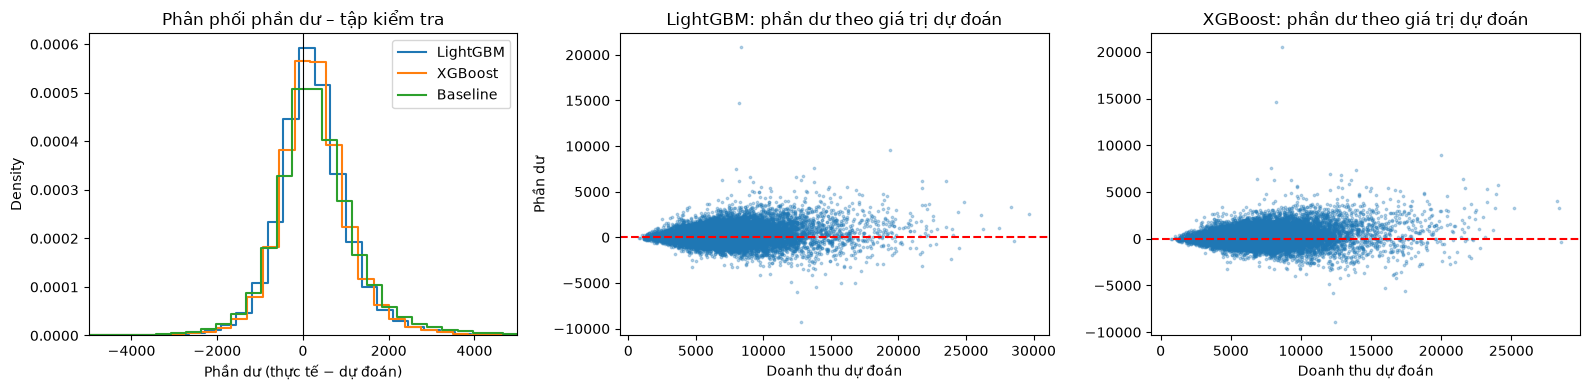

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name in FOCUS:
    sns.histplot(test['actual'] - test[name], bins=120, stat='density', element='step', fill=False,
                 label=name, ax=axes[0])
axes[0].set_xlim(-5000, 5000); axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_xlabel('Phần dư (thực tế − dự đoán)'); axes[0].set_title('Phân phối phần dư – tập kiểm tra')
axes[0].legend()

sample = test.sample(20_000, random_state=0)
for ax, name in zip(axes[1:], TOP):
    ax.scatter(sample[name], sample['actual'] - sample[name], s=3, alpha=0.3)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_title(f'{name}: phần dư theo giá trị dự đoán'); ax.set_xlabel('Doanh thu dự đoán')
axes[1].set_ylabel('Phần dư')
save_fig('residuals')

**Nhận xét:** phần dư có dạng chuông quanh 0, nhưng **hơi lệch về phía dương**: LightGBM dự đoán thấp hơn thực tế ở 62% số ngày, phần dư trung bình +266, tức thấp hơn khoảng 2,4%. Các mô hình cây khác và Baseline cũng vậy. Nguyên nhân là doanh thu giữa năm 2015 cao hơn mức đã học (EDA đã thấy xu hướng tăng nhẹ), trong khi mô hình cây không kéo dài được xu hướng ra ngoài khoảng đã học. Riêng **Hybrid gần như không lệch** (+47, 51% số ngày dự đoán thấp hơn), nhờ phần hồi quy tuyến tính học được xu hướng. Đây là ưu điểm duy nhất của Hybrid trong kết quả này. Hướng cải thiện đơn giản: nhân dự đoán với một hệ số hiệu chỉnh (khoảng 1,02) tính trên tập kiểm định, đây là kỹ thuật phổ biến trong cuộc thi Rossmann.

**5.5 Mô hình yếu ở đâu?**

Tính sai số theo từng nhóm: mức doanh thu, thứ trong tuần, khuyến mãi, loại cửa hàng. Dùng **MAE / doanh thu trung bình của nhóm (%)** để so được giữa nhóm doanh thu cao và thấp.

In [9]:
test['Mức doanh thu'] = pd.qcut(test['actual'], 5, labels=['Rất thấp', 'Thấp', 'Trung bình', 'Cao', 'Rất cao'])
test['Thứ'] = test['DayOfWeek'].map(dict(zip(range(1, 8), ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN'])))
test['Khuyến mãi'] = test['Promo'].map({0: 'Không', 1: 'Có'})

def error_table(key):
    g = test.groupby(key, observed=True)
    out = pd.DataFrame({name: g.apply(lambda d: mean_absolute_error(d['actual'], d[name]) / d['actual'].mean() * 100,
                                      include_groups=False) for name in FOCUS})
    out['Số dòng'] = g.size()
    return out.round(1)

for key in ['Mức doanh thu', 'Thứ', 'Khuyến mãi', 'StoreType']:
    print(f'--- MAE / trung bình (%) theo {key}')
    print(error_table(key), '\n')

--- MAE / trung bình (%) theo Mức doanh thu
               LightGBM  XGBoost  Baseline  Số dòng
Mức doanh thu                                      
Rất thấp            9.7      9.5      11.2     9400
Thấp                8.8      8.7      10.1     9406
Trung bình          8.6      8.7       9.8     9395
Cao                 8.7      8.8      10.2     9397
Rất cao             9.9      9.8      12.0     9400 

--- MAE / trung bình (%) theo Thứ
     LightGBM  XGBoost  Baseline  Số dòng
Thứ                                      
CN       10.1     10.5      15.7      225
T2       10.1      9.9      11.3     7796
T3       10.0      9.7      12.0     7796
T4        8.9      9.0      10.2     7796
T5        8.6      8.8      10.0     7794
T6        8.1      8.1      10.8     7795
T7        9.3      9.2      10.2     7796 

--- MAE / trung bình (%) theo Khuyến mãi
            LightGBM  XGBoost  Baseline  Số dòng
Khuyến mãi                                      
Có               9.3      9.2      11

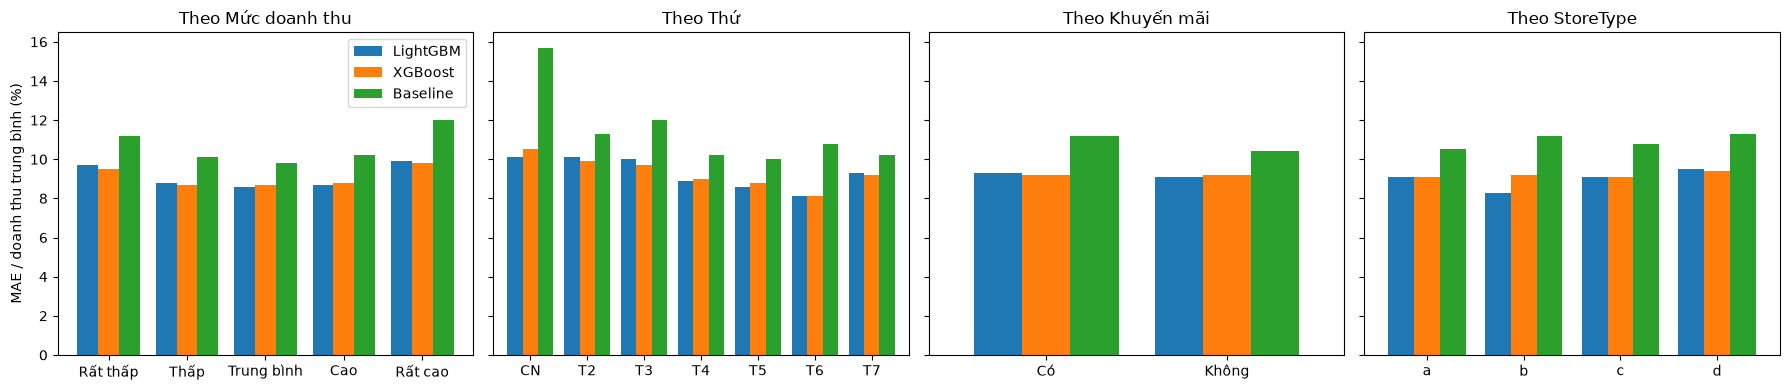

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, key in zip(axes, ['Mức doanh thu', 'Thứ', 'Khuyến mãi', 'StoreType']):
    error_table(key)[FOCUS].plot.bar(ax=ax, rot=0, width=0.8, legend=(key == 'Mức doanh thu'))
    ax.set_title(f'Theo {key}'); ax.set_xlabel('')
axes[0].set_ylabel('MAE / doanh thu trung bình (%)')
save_fig('error_by_group')

**Nhận xét:**
- **Mức doanh thu:** sai số tương đối có dạng chữ U. Nhóm giữa sai khoảng 8,6–8,8%, còn hai đầu cao hơn: nhóm "Rất thấp" 9,7% và "Rất cao" 9,9%. Mô hình yếu nhất ở những ngày doanh thu đột biến, cao hoặc thấp bất thường.
- **Thứ:** thứ Hai và thứ Ba khó đoán nhất (khoảng 10%), thứ Sáu dễ nhất (8,1%). Chủ nhật chỉ có 225 dòng, nhưng LightGBM giảm sai số so với Baseline nhiều nhất ở đây (10,1% so với 15,7%).
- **Khuyến mãi:** sai số ngày có và không có khuyến mãi gần như bằng nhau (9,3% và 9,1%), nên các đặc trưng khuyến mãi (`PromoRun`, `LastPromo`…) đã mô tả tốt tác động của khuyến mãi.
- **Loại cửa hàng:** khá đều (8,3–9,5%). Loại b (17 cửa hàng) là nơi LightGBM tốt hơn XGBoost rõ nhất (8,3% so với 9,2%).

**5.6 Sai số theo khoảng cách dự báo**

Tập kiểm tra dài 7 tuần (13/06 – 31/07/2015). Mọi độ trễ đều từ 49 ngày bán trở lên, nên đây là dự báo **thật sự trước nhiều tuần**: ngày cuối của tập kiểm tra cách ngày cuối của dữ liệu đã biết khoảng 7 tuần. Nếu mô hình tốt, sai số không được tăng mạnh theo thời gian.

,LightGBM,XGBoost,Baseline
Tuần thứ,,,
1,0.1108,0.1096,0.1131
2,0.1048,0.1078,0.1213
3,0.1319,0.1277,0.1635
4,0.1395,0.1356,0.1576
5,0.1094,0.1080,0.1292
6,0.1139,0.1152,0.1386
7,0.1306,0.1287,0.1687


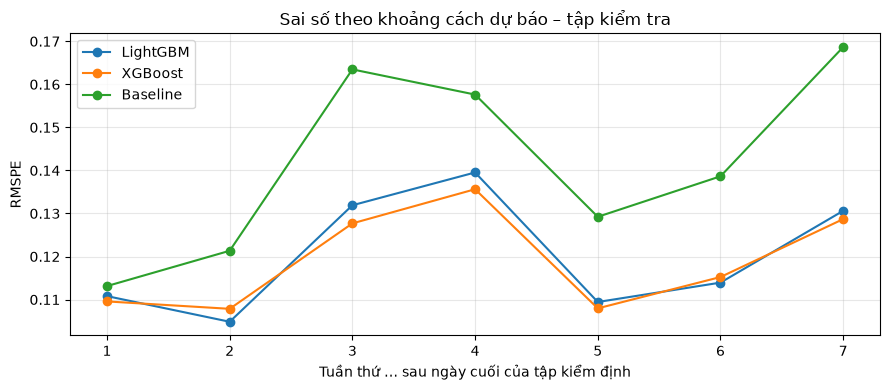

In [11]:
test['Tuần thứ'] = ((test['Date'] - VALID_END).dt.days - 1) // 7 + 1
by_week = pd.DataFrame({name: test.groupby('Tuần thứ').apply(lambda d: rmspe(d['actual'], d[name]), include_groups=False)
                        for name in FOCUS})
ax = by_week.plot(marker='o', figsize=(9, 4))
ax.set_xlabel('Tuần thứ … sau ngày cuối của tập kiểm định'); ax.set_ylabel('RMSPE')
ax.set_title('Sai số theo khoảng cách dự báo – tập kiểm tra'); ax.grid(alpha=0.3)
save_fig('error_by_horizon')
by_week.round(4)

**Nhận xét:** sai số **không tăng dần** theo khoảng cách dự báo: tuần 1–2 khoảng 0,105–0,11, tuần 3–4 tăng lên 0,13–0,14, tuần 5–6 giảm lại khoảng 0,11, tuần 7 khoảng 0,13. Baseline cũng cao lên ở đúng các tuần 3, 4 và 7, nên đây là những tuần **vốn khó đoán**, ví dụ tuần 3 (27/06–03/07) có đợt doanh thu tăng vọt của cửa hàng 292, chứ không phải do dự báo xa. Như vậy độ trễ ≥ 49 ngày giúp mô hình giữ được chất lượng trong cả khoảng 7 tuần, đúng yêu cầu dự báo trước 6 tuần. Tuần nào LightGBM và XGBoost cũng tốt hơn Baseline.

**5.7 Sai số theo từng cửa hàng**

LightGBM: RMSPE theo cửa hàng
count    1115.0000
mean        0.1145
std         0.0448
min         0.0596
50%         0.1064
90%         0.1484
99%         0.2488
max         0.9396
Name: RMSPE, dtype: float64
Số cửa hàng LightGBM tốt hơn Baseline: 927 / 1115


10 cửa hàng sai nhiều nhất:


,RMSPE,RMSPE Baseline,Doanh thu TB,StoreType
Store,,,,
292,0.940,0.946,7156.625,a
909,0.706,0.655,15099.214,a
782,0.426,0.458,5504.095,c
876,0.423,0.408,11186.107,a
722,0.308,0.320,7602.357,a
274,0.291,0.353,5836.122,b
286,0.283,0.365,3782.881,a
1014,0.279,0.286,10340.571,a
563,0.277,0.356,4432.643,a


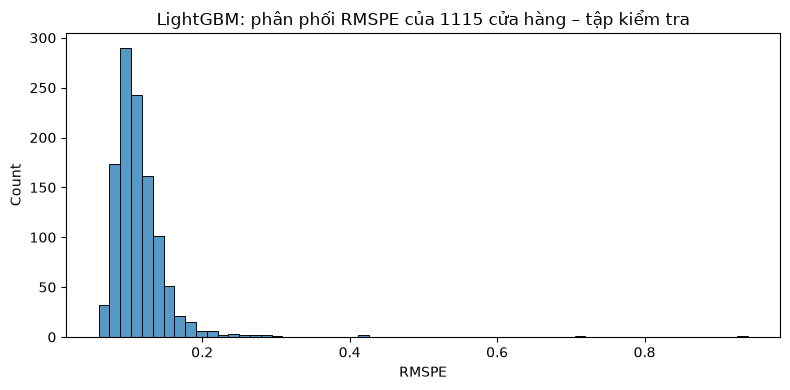

In [12]:
best = TOP[0]
store_err = test.groupby('Store').apply(lambda d: pd.Series({'RMSPE': rmspe(d['actual'], d[best]),
                                                             'RMSPE Baseline': rmspe(d['actual'], d['Baseline']),
                                                             'Doanh thu TB': d['actual'].mean(),
                                                             'StoreType': d['StoreType'].iloc[0]}),
                                        include_groups=False)
store_err[['RMSPE', 'RMSPE Baseline', 'Doanh thu TB']] = store_err[['RMSPE', 'RMSPE Baseline', 'Doanh thu TB']].astype(float)
print(f'{best}: RMSPE theo cửa hàng')
print(store_err['RMSPE'].describe(percentiles=[0.5, 0.9, 0.99]).round(4))
print(f'Số cửa hàng {best} tốt hơn Baseline: {(store_err["RMSPE"] < store_err["RMSPE Baseline"]).sum()} / {len(store_err)}')

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(store_err['RMSPE'], bins=60, ax=ax)
ax.set_title(f'{best}: phân phối RMSPE của {len(store_err)} cửa hàng – tập kiểm tra')
save_fig('error_by_store')
print('10 cửa hàng sai nhiều nhất:')
store_err.sort_values('RMSPE', ascending=False).head(10).round(3)

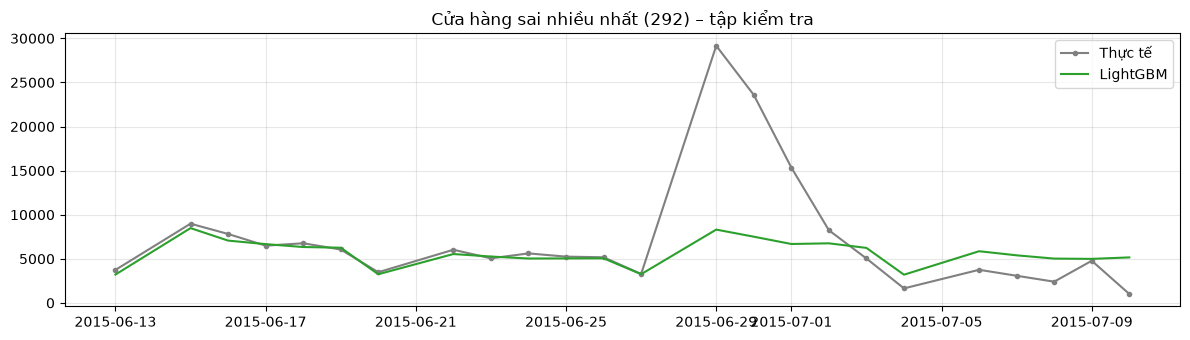

In [13]:
worst = store_err['RMSPE'].idxmax()
s = test[test['Store'] == worst]
plt.figure(figsize=(12, 3.5))
plt.plot(s['Date'], s['actual'], color='gray', marker='.', label='Thực tế')
plt.plot(s['Date'], s[best], color='tab:green', label=best)
plt.title(f'Cửa hàng sai nhiều nhất ({worst}) – tập kiểm tra'); plt.legend(); plt.grid(alpha=0.3)
save_fig('worst_store')

**Nhận xét:** với LightGBM, một nửa số cửa hàng có RMSPE dưới 0,106 và 90% số cửa hàng dưới 0,148. LightGBM tốt hơn Baseline ở **927/1.115 cửa hàng (83%)**. Một vài cửa hàng có sai số rất lớn kéo RMSPE chung lên, vì RMSPE nhạy với các ngày bị dự đoán lệch nhiều.
- Cửa hàng 292 (RMSPE 0,94): doanh thu vọt lên 29.144 ngày 29/06, gấp khoảng 5 lần mức thường (trung vị 5.862), rồi giảm dần và đóng cửa liên tục từ 11/07. Có thể là đợt bán xả hàng trước khi đóng cửa dài ngày.
- Cửa hàng 909 (0,71) có diễn biến tương tự.

Không đặc trưng nào báo trước được những sự kiện này, nên mọi mô hình kể cả Baseline đều sai. Thực tế cần nguồn thông tin bổ sung, ví dụ lịch sửa chữa hoặc đóng cửa của cửa hàng.

**5.8 So sánh thực tế và dự đoán theo thời gian**

Sai số trung bình của TỔNG doanh thu toàn chuỗi mỗi ngày (%):


LightGBM    4.80
XGBoost     4.87
Baseline    6.55
dtype: float64

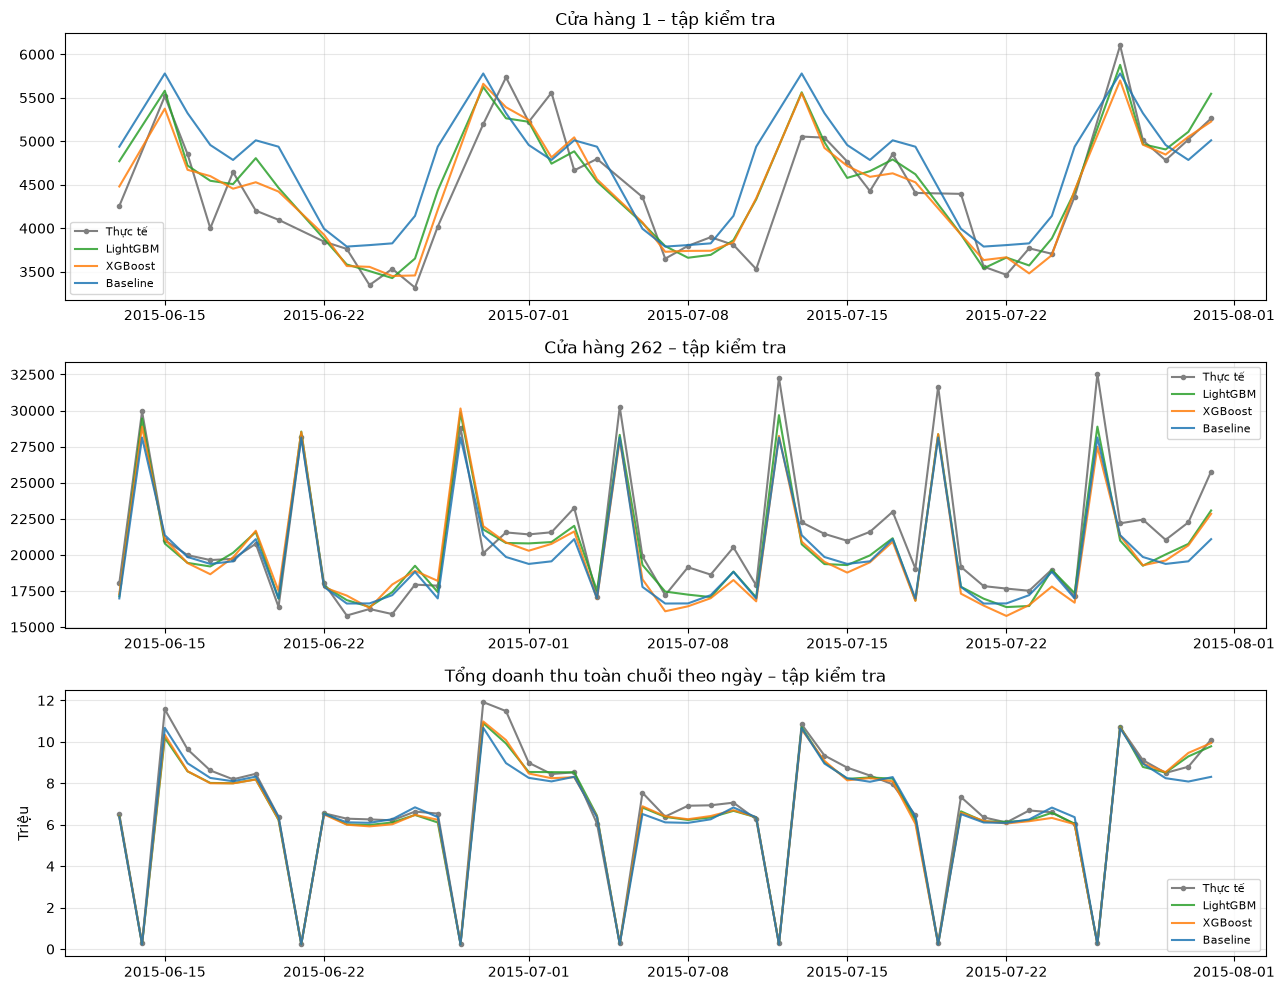

In [14]:
colors = {TOP[0]: 'tab:green', TOP[1]: 'tab:orange', 'Baseline': 'tab:blue'}
fig, axes = plt.subplots(3, 1, figsize=(13, 10))
for ax, store_id in zip(axes[:2], [1, 262]):
    s = test[test['Store'] == store_id]
    ax.plot(s['Date'], s['actual'], color='gray', marker='.', label='Thực tế')
    for name in FOCUS:
        ax.plot(s['Date'], s[name], color=colors[name], alpha=0.85, label=name)
    ax.set_title(f'Cửa hàng {store_id} – tập kiểm tra'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

daily_total = test.groupby('Date')[['actual'] + FOCUS].sum() / 1e6
axes[2].plot(daily_total.index, daily_total['actual'], color='gray', marker='.', label='Thực tế')
for name in FOCUS:
    axes[2].plot(daily_total.index, daily_total[name], color=colors[name], alpha=0.85, label=name)
axes[2].set_title('Tổng doanh thu toàn chuỗi theo ngày – tập kiểm tra'); axes[2].set_ylabel('Triệu')
axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)
save_fig('store_forecast')

total_err = (daily_total[FOCUS].sub(daily_total['actual'], axis=0).abs().div(daily_total['actual'], axis=0) * 100).mean()
print('Sai số trung bình của TỔNG doanh thu toàn chuỗi mỗi ngày (%):')
total_err.round(2)

**Nhận xét:** ở cửa hàng 1 và 262, LightGBM và XGBoost bám sát thực tế và gần như trùng nhau. Baseline đi theo bậc thang vì chỉ lấy trung vị theo thứ và khuyến mãi. Với **tổng doanh thu toàn chuỗi** mỗi ngày, sai số chỉ còn 4,8% (LightGBM) so với 6,55% (Baseline), vì sai số của từng cửa hàng bù trừ cho nhau. Đường dự đoán tổng nằm hơi thấp hơn thực tế, khớp với độ lệch khoảng 2,4% ở mục 5.4. Mô hình đủ tốt cho việc lập kế hoạch ở cấp toàn chuỗi (dự trù doanh thu, hàng hoá, dòng tiền 6 tuần tới).

**5.9 Thử kết hợp hai mô hình tốt nhất**

Lấy trung bình dự đoán của hai mô hình tốt nhất (chọn theo tập kiểm định). Nếu hai mô hình sai theo những cách khác nhau, trung bình của chúng có thể tốt hơn từng mô hình.

In [15]:
print(f'Tương quan phần dư {TOP[0]} – {TOP[1]} trên tập kiểm định:',
      round((results.query("Split == 'valid'")['actual'] - results.query("Split == 'valid'")[TOP[0]])
            .corr(results.query("Split == 'valid'")['actual'] - results.query("Split == 'valid'")[TOP[1]]), 3))
results['Kết hợp'] = results[TOP].mean(axis=1)
combo = pd.DataFrame({name: {split: rmspe(part['actual'], part[name]) for split, part in results.groupby('Split', sort=False)}
                      for name in TOP + ['Kết hợp']}).T
combo[['valid', 'test']].round(4)

Tương quan phần dư LightGBM – XGBoost trên tập kiểm định: 0.917


,valid,test
LightGBM,0.1064,0.1208
XGBoost,0.1077,0.1194
Kết hợp,0.1051,0.1189


**Nhận xét:** phần dư của LightGBM và XGBoost tương quan rất cao (0,917), tức hai mô hình sai ở gần như cùng những ngày. Vì vậy kết hợp chỉ cải thiện rất ít: RMSPE trên tập kiểm định 0,1051 (so với 0,1064) và trên tập kiểm tra 0,1189 (so với 0,1194 của XGBoost), khoảng 1%. Kết hợp vẫn đáng thử khi nộp Kaggle vì gần như không tốn thêm công, nhưng muốn cải thiện nhiều hơn thì cần mô hình khác loại (sai theo cách khác) hoặc thêm đặc trưng mới.

**5.10 Kiểm tra các file nộp Kaggle**

Notebook 4 đã tạo file nộp cho từng mô hình (`submissions/`). Kiểm tra số dòng, giá trị bất thường và mức giống nhau giữa các mô hình. Điểm thật trên Kaggle (Public/Private score) được phân tích ở mục 5.11.

In [16]:
SUB_DIR = Path('submissions')
subs = {p.stem.replace('submission_', ''): pd.read_csv(p).set_index('Id')['Sales'] for p in sorted(SUB_DIR.glob('submission_*.csv'))}
subs = pd.DataFrame(subs)
print('Số dòng mỗi file:', len(subs), '| thiếu giá trị:', int(subs.isna().sum().sum()), '| giá trị âm:', int((subs < 0).sum().sum()))
print('Số ngày đóng cửa (Sales = 0):', int((subs['lightgbm'] == 0).sum()))
display(subs[subs['lightgbm'] > 0].describe().T.round(0))
print('Tương quan giữa các file nộp (ngày mở cửa):')
subs[subs['lightgbm'] > 0].corr().round(3)

Số dòng mỗi file: 41088 | thiếu giá trị: 0 | giá trị âm: 0
Số ngày đóng cửa (Sales = 0): 5984


,count,mean,std,min,25%,50%,75%,max
baseline,35104.0,6670.0,2645.0,1341.0,4878.0,6187.0,7903.0,28132.0
hybrid,35104.0,6840.0,2666.0,1091.0,5059.0,6388.0,8049.0,32041.0
lightgbm,35104.0,6691.0,2674.0,1107.0,4903.0,6188.0,7893.0,30062.0
random_forest,35104.0,6690.0,2687.0,1111.0,4885.0,6174.0,7873.0,30177.0
ridge,35104.0,6555.0,2589.0,1972.0,4800.0,6045.0,7724.0,30445.0
xgboost,35104.0,6683.0,2692.0,1092.0,4873.0,6168.0,7898.0,29135.0


Tương quan giữa các file nộp (ngày mở cửa):


,baseline,hybrid,lightgbm,random_forest,ridge,xgboost
baseline,1.000,0.931,0.980,0.982,0.951,0.978
hybrid,0.931,1.000,0.957,0.945,0.935,0.954
lightgbm,0.980,0.957,1.000,0.990,0.954,0.995
random_forest,0.982,0.945,0.990,1.000,0.952,0.988
ridge,0.951,0.935,0.954,0.952,1.000,0.950
xgboost,0.978,0.954,0.995,0.988,0.950,1.000


**Nhận xét:** 6 file nộp đều đủ 41.088 dòng, không thiếu giá trị, không có số âm; 5.984 dòng đóng cửa được gán 0. Trung bình dự đoán cho các ngày mở cửa khoảng 6.700 ở các mô hình cây và Baseline. Hybrid cao hơn (6.840), khớp với việc Hybrid không bị lệch thấp; Ridge thấp nhất (6.555). LightGBM và XGBoost cho dự đoán gần như giống hệt nhau (tương quan 0,995). Kết quả khi nộp thật lên Kaggle được phân tích ở mục 5.11.

**5.11 Đánh giá trên tập thi thật (Kaggle)**

Cả 6 file nộp đã được nộp lên cuộc thi Rossmann Store Sales (dạng *Late Submission*). Kaggle chấm RMSPE trên tập thi **01/08 – 17/09/2015** (856 cửa hàng, ngày có doanh thu 0 không tính), chia làm hai phần: **Public** (hiện ngay khi nộp) và **Private** (điểm xếp hạng cuối cùng, mô hình chưa từng được "nhìn" thấy). Coi điểm **Private là kết quả trên tập thi thật**, rồi so với các điểm nội bộ ở mục 5.2 để xem:
- **Độ ổn định:** thứ hạng có giữ nguyên không, điểm Public và Private chênh nhau bao nhiêu.
- **Độ lệch so với dự đoán ban đầu:** điểm thật cao hơn hay thấp hơn RMSPE trên tập kiểm định / kiểm tra bao nhiêu %.

Lưu ý: mô hình chỉ học dữ liệu đến **24/04/2015** (không học lại trên toàn bộ dữ liệu trước khi nộp). Tập kiểm định cách ngày cuối train 1–7 tuần, tập kiểm tra 7–14 tuần, còn tập Kaggle 14–21 tuần.

In [17]:
# Điểm nộp trên Kaggle (RMSPE)
kaggle_scores = pd.DataFrame({
    'Public':  {'Baseline': 0.14446, 'Hybrid': 0.14332, 'LightGBM': 0.12336,
                'Ridge': 0.16723, 'Random Forest': 0.13036, 'XGBoost': 0.12395},
    'Private': {'Baseline': 0.15085, 'Hybrid': 0.14600, 'LightGBM': 0.12542,
                'Ridge': 0.16824, 'Random Forest': 0.13563, 'XGBoost': 0.12765},
})
kaggle_scores.to_csv(PROCESSED_DIR / 'kaggle_scores.csv', index_label='Mô hình')

real = metrics.pivot(index='Mô hình', columns='Tập', values='RMSPE')[['valid', 'test']].join(kaggle_scores).loc[order]
real['Private so với valid (%)'] = (real['Private'] / real['valid'] - 1) * 100
real['Private so với test (%)'] = (real['Private'] / real['test'] - 1) * 100
real['Private so với Public (%)'] = (real['Private'] / real['Public'] - 1) * 100
real['Cải thiện Private so với baseline (%)'] = 100 * (1 - real['Private'] / real.loc['Baseline', 'Private'])
print('RMSPE nội bộ (valid, test) và trên Kaggle (Public, Private), sắp theo tập kiểm định:')
real.round({'valid': 4, 'test': 4, 'Public': 5, 'Private': 5, 'Private so với valid (%)': 1,
            'Private so với test (%)': 1, 'Private so với Public (%)': 1, 'Cải thiện Private so với baseline (%)': 1})

RMSPE nội bộ (valid, test) và trên Kaggle (Public, Private), sắp theo tập kiểm định:

,valid,test,Public,Private,Private so với valid (%),Private so với test (%),Private so với Public (%),Cải thiện Private so với baseline (%)
Mô hình,,,,,,,,
LightGBM,0.1064,0.1208,0.12336,0.12542,17.9,3.8,1.7,16.9
XGBoost,0.1077,0.1194,0.12395,0.12765,18.5,6.9,3.0,15.4
Random Forest,0.1232,0.1281,0.13036,0.13563,10.1,5.8,4.0,10.1
Hybrid,0.1521,0.1525,0.14332,0.14600,-4.0,-4.2,1.9,3.2
Baseline,0.1663,0.1432,0.14446,0.15085,-9.3,5.4,4.4,0.0
Ridge,0.1941,0.1895,0.16723,0.16824,-13.3,-11.2,0.6,-11.5


In [18]:
rank = real[['valid', 'test', 'Public', 'Private']].rank().astype(int)
print('Thứ hạng của mô hình trên từng tập (1 = tốt nhất):')
print(rank, '\n')
print('Tương quan hạng Spearman với thứ hạng Private:')
rank.corr(method='spearman')['Private'].round(3)

Thứ hạng của mô hình trên từng tập (1 = tốt nhất):
               valid  test  Public  Private
Mô hình                                    
LightGBM           1     2       1        1
XGBoost            2     1       2        2
Random Forest      3     3       3        3
Hybrid             4     5       4        4
Baseline           5     4       5        5
Ridge              6     6       6        6 

Tương quan hạng Spearman với thứ hạng Private:

valid      1.000
test       0.886
Public     1.000
Private    1.000
Name: Private, dtype: float64

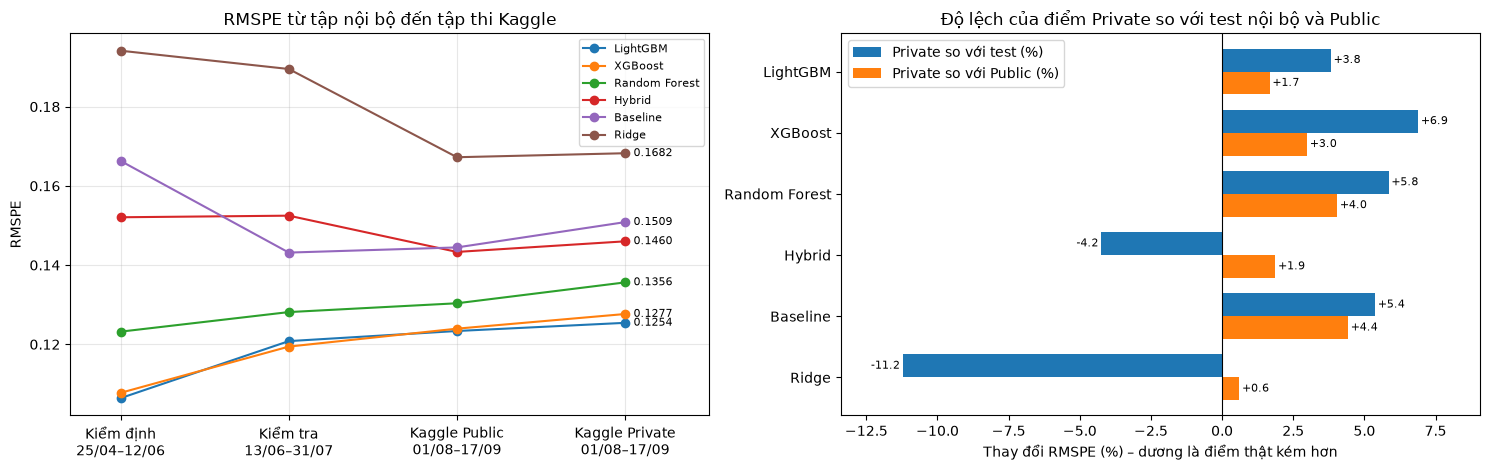

In [19]:
stages = ['valid', 'test', 'Public', 'Private']
labels = ['Kiểm định\n25/04–12/06', 'Kiểm tra\n13/06–31/07', 'Kaggle Public\n01/08–17/09', 'Kaggle Private\n01/08–17/09']
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for name in order:
    axes[0].plot(labels, real.loc[name, stages], marker='o', label=name)
    axes[0].annotate(f"{real.loc[name, 'Private']:.4f}", (3, real.loc[name, 'Private']),
                     xytext=(6, 0), textcoords='offset points', va='center', fontsize=8)
axes[0].set_ylabel('RMSPE'); axes[0].set_title('RMSPE từ tập nội bộ đến tập thi Kaggle')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

shift = real[['Private so với test (%)', 'Private so với Public (%)']]
shift.plot.barh(ax=axes[1], width=0.75)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%+.1f', fontsize=8, padding=2)
axes[1].margins(x=0.12); axes[0].set_xlim(-0.3, 3.5)
axes[1].axvline(0, color='black', lw=0.8); axes[1].invert_yaxis()
axes[1].set_xlabel('Thay đổi RMSPE (%) – dương là điểm thật kém hơn'); axes[1].set_ylabel('')
axes[1].set_title('Độ lệch của điểm Private so với test nội bộ và Public')
save_fig('kaggle_vs_local')

**Nhận xét – độ ổn định:**
- **Thứ hạng trên Kaggle trùng hoàn toàn với thứ hạng trên tập kiểm định**, ở cả Public lẫn Private: LightGBM > XGBoost > Random Forest > Hybrid > Baseline > Ridge (Spearman = 1,0). Tập kiểm tra nội bộ đảo hai cặp vốn sát nút (XGBoost/LightGBM và Baseline/Hybrid), Spearman 0,886. Như vậy cách chọn mô hình **theo tập kiểm định** ở mục 5.4 là đúng: **LightGBM là mô hình tốt nhất trên tập thi thật** (Private 0,12542).
- **Public → Private:** mọi mô hình đều kém đi một chút, từ 0,6% đến 4,4%, không mô hình nào đổi hạng. Ổn định nhất là Ridge (+0,6%), LightGBM (+1,7%) và Hybrid (+1,9%); biến động nhiều hơn là XGBoost (+3,0%), Random Forest (+4,0%) và Baseline (+4,4%). Vì thế khoảng cách LightGBM – XGBoost nới rộng từ 0,0006 (Public) lên 0,0022 (Private).
- Điều này **khớp với mục 5.3**: hai mô hình quá khớp nhất (XGBoost và Random Forest, test/train ≈ 1,7) cũng là hai mô hình cây giảm chất lượng nhiều nhất khi sang dữ liệu mới, còn LightGBM (test/train 1,34) giữ ổn định hơn.

**Nhận xét – độ lệch so với dự đoán ban đầu:**
- So với tập kiểm tra nội bộ, điểm Private của các mô hình cây **cao hơn 3,8–6,9%**: LightGBM 0,1208 → 0,1254 (+3,8%), Random Forest 0,1281 → 0,1356 (+5,8%), XGBoost 0,1194 → 0,1277 (+6,9%); Baseline cũng tăng 5,4%. So với tập kiểm định thì độ lệch lớn hơn (+18% với LightGBM và XGBoost). Tập kiểm tra nội bộ là **ước lượng hơi lạc quan nhưng đáng tin**: sai lệch nhỏ và giữ đúng thứ tự giữa các mô hình cây.
- Nguyên nhân chính là **khoảng cách thời gian**: mô hình học đến 24/04/2015 rồi dự báo xa 14–21 tuần, xa hơn tập kiểm tra (7–14 tuần). Các đặc trưng trễ vẫn mới (độ trễ ≥ 49 ngày lấy từ tháng 6–7), nhưng mức doanh thu nền mà mô hình cây học được đã cũ, nên độ lệch thấp khoảng 2,4% (mục 5.4) có xu hướng lớn dần theo thời gian. Ngoài ra tháng 8–9 rơi vào kỳ nghỉ hè, khác với giai đoạn của tập kiểm định và kiểm tra.
- Ngược lại, **Hybrid và Ridge tốt hơn trên tập thi**: Hybrid 0,1525 → 0,1460 (−4,2%), Ridge 0,1895 → 0,1682 (−11,2%). Hai mô hình này có phần tuyến tính theo thời gian, ngoại suy được xu hướng, nên dự báo càng xa càng có lợi so với mô hình cây. Nhờ vậy trên Kaggle **Hybrid đã vượt Baseline** (0,1460 so với 0,1509), điều mà tập kiểm tra nội bộ chưa cho thấy.
- Mức cải thiện của LightGBM so với Baseline trên Private là **16,9%**, gần với 15,6% trên tập kiểm tra. Lợi ích thực tế của mô hình so với cách làm đơn giản đúng như đã ước lượng.

## 5.12 Kết luận

- **LightGBM và XGBoost là hai mô hình tốt nhất**, gần như ngang nhau: RMSPE trên tập kiểm tra khoảng 0,12, MAE khoảng 9% doanh thu trung bình, giảm RMSPE 16–17% so với Baseline (35–36% trên tập kiểm định). **Chọn LightGBM làm mô hình chính** vì tốt nhất trên tập kiểm định và quá khớp ít hơn XGBoost (test/train 1,34 so với 1,74).
- **Kết quả trên tập thi thật (Kaggle) xác nhận lựa chọn này:** LightGBM đứng đầu với Private 0,12542 (Public 0,12336), thứ hạng 6 mô hình trên Kaggle trùng hoàn toàn với thứ hạng trên tập kiểm định. Điểm thật chỉ kém tập kiểm tra nội bộ 3,8% và chênh Public – Private 1,7%, nên LightGBM là mô hình ổn định nhất trong nhóm mô hình cây.
- **Hybrid và Ridge không tốt hơn Baseline** trên tập kiểm tra. Mô hình phức tạp hơn không có nghĩa là tốt hơn; điểm mạnh duy nhất của Hybrid là không bị lệch thấp nhờ học được xu hướng, và ưu điểm này lộ rõ khi dự báo xa hơn: trên Kaggle Hybrid đã vượt Baseline.
- **Dự báo trước 6 tuần dùng được:** sai số không tăng dần trong 7 tuần của tập kiểm tra; ở cấp toàn chuỗi, sai số tổng doanh thu mỗi ngày chỉ khoảng 4,8%.
- **Hạn chế:**
  - Các mô hình cây dự đoán thấp hơn thực tế khoảng 2,4% vì không ngoại suy được xu hướng tăng.
  - XGBoost và Random Forest quá khớp, và giảm chất lượng nhiều hơn khi sang tập thi (+5,8–6,9% so với tập kiểm tra).
  - Một vài cửa hàng có sự kiện bất thường (doanh thu tăng vọt rồi đóng cửa dài ngày) làm RMSPE chung tăng lên.
- **Hướng cải thiện:** huấn luyện lại trên toàn bộ dữ liệu đến 31/07/2015 trước khi nộp, để giảm khoảng cách 14–21 tuần giữa dữ liệu học và tập thi; nhân hệ số hiệu chỉnh khoảng 1,02 (tính trên tập kiểm định); tăng điều chuẩn cho XGBoost và Random Forest; kết hợp LightGBM và XGBoost khi nộp Kaggle; bổ sung thông tin về lịch đóng cửa, sửa chữa của cửa hàng.
- **So với đồ án 2** (dự báo ngắn hạn): khi chỉ cần dự báo ngày mai, độ trễ 1 ngày giúp RMSPE doanh thu giảm xuống khoảng 0,106. Mức 0,12 ở đây là cái giá của việc phải dự báo trước 6 tuần.